In [1]:
#new_code

In [2]:
import os
import gc
import sys
from PIL import Image
import cv2
import math, random
import numpy as np
import pandas as pd
from glob import glob
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from collections import OrderedDict
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torch.optim import AdamW
import timm
from timm.utils import ModelEmaV2
from transformers import get_cosine_schedule_with_warmup
import albumentations as A
from sklearn.model_selection import KFold
import re
import pydicom
import glob

In [3]:
rd = '/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification'
OUTPUT_DIR = f'/kaggle/input/rsna2024-lsdc-training-baseline/rsna2024-results'
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
N_WORKERS = os.cpu_count()
USE_AMP = True
SEED = 8620
IMG_SIZE = [256, 256]
IN_CHANS = 42
N_LABELS = 5                     # Phase 1 bridge: one sample = (study, disc level) -> 5 conditions
N_CLASSES = 3 * N_LABELS         # 15 logits (5 conditions x 3 severity classes)
N_FOLDS = 5
MODEL_NAME = "edgenext_base.in21k_ft_in1k"

BATCH_SIZE = 1
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
device
df = pd.read_csv(f'{rd}/test_series_descriptions.csv')
df.head()
study_ids = list(df['study_id'].unique())
sample_sub = pd.read_csv(f'{rd}/sample_submission.csv')
LABELS = list(sample_sub.columns[1:])
LABELS


['normal_mild', 'moderate', 'severe']

In [4]:
CONDITIONS = [
    'spinal_canal_stenosis', 
    'left_neural_foraminal_narrowing', 
    'right_neural_foraminal_narrowing',
    'left_subarticular_stenosis',
    'right_subarticular_stenosis'
]

LEVELS = [
    'l1_l2',
    'l2_l3',
    'l3_l4',
    'l4_l5',
    'l5_s1',
]

In [5]:
def atoi(text):
    return int(text) if text.isdigit() else text

def natural_keys(text):
    return [ atoi(c) for c in re.split(r'(\d+)', text) ]

In [ ]:

import numpy as np, pandas as pd, cv2

try:
    PHASE1_COORD_CSV = cfg['phase1_coord_csv']
    CROP_PX, MODEL_PX, PHASE1_MPE, TRAIN_JIT = cfg['crop_px'], cfg['model_px'], cfg['phase1_mpe'], cfg['train_jit']
except Exception:
    PHASE1_COORD_CSV = '/kaggle/input/rsna-phase1-coordinates/stage3_coor_with_depth.csv'

CROP_PX    = 96      # crop side, measured on the 256x256 canvas
MODEL_PX   = 256     # crop is resized back to 256x256 -> models / transforms / loss stay identical to baseline
PHASE1_MPE = 6.88    # px @256; emulates Phase 1 error only where a prediction is missing
TRAIN_JIT  = 3.0     # px @256; train-time jitter so the classifier tolerates Phase 1 error

p1 = pd.read_csv(PHASE1_COORD_CSV)
P1_XY = {(r.study_id, r.series_id, r.condition, r.level): (r.x, r.y) for r in p1.itertuples()}
print(f'Phase 1 coordinates loaded: {len(P1_XY):,}')

def crop_around(img, cx, cy, jitter=0.0):
    """img: HxW uint8. (cx, cy) in img pixels. Returns MODEL_PX x MODEL_PX crop centred on (cx, cy)."""
    H, W = img.shape[:2]
    canvas = cv2.resize(img, (MODEL_PX, MODEL_PX), interpolation=cv2.INTER_LINEAR)
    cx, cy = cx * MODEL_PX / W, cy * MODEL_PX / H
    if jitter > 0:
        cx += np.random.normal(0, jitter); cy += np.random.normal(0, jitter)
    half = CROP_PX // 2
    pad = np.pad(canvas, ((half, half), (half, half)), mode='edge')
    x0 = int(np.clip(round(cx), 0, MODEL_PX)); y0 = int(np.clip(round(cy), 0, MODEL_PX))
    patch = pad[y0:y0 + CROP_PX, x0:x0 + CROP_PX]
    return cv2.resize(patch, (MODEL_PX, MODEL_PX), interpolation=cv2.INTER_LINEAR)

def phase1_center(row, W, H):
    """Phase 1 predicted (x, y); falls back to the label + Phase-1-sized error if a prediction is missing."""
    k = (row['study_id'], row['series_id'], row['condition'], row['level'])
    if k in P1_XY:
        return P1_XY[k]
    s = PHASE1_MPE / np.sqrt(2) / MODEL_PX
    return row['x'] + np.random.normal(0, s * W), row['y'] + np.random.normal(0, s * H)

def audit_phase1_coverage(df, label=""):
    """Report how often stage3_coor.csv supplies (x,y) vs label+noise fallback."""
    keys = list(zip(df["study_id"], df["series_id"], df["condition"], df["level"]))
    hit = sum(1 for k in keys if k in P1_XY)
    n = len(keys)
    miss = n - hit
    pct = 100.0 * hit / n if n else 0.0
    print(
        f"Phase 1 CSV coverage{label}: {hit:,}/{n:,} ({pct:.2f}%) from stage3_coor.csv; "
        f"{miss:,} rows use label-centre + noise fallback (MPE={PHASE1_MPE}px @256, not every row)"
    )
    return hit, miss

# Prefer Approach 3 bridge paths from Phase 2 config when available
if "PHASE2_CFG" in globals():
    PHASE1_COORD_CSV = PHASE2_CFG.get("phase1_coord_csv", PHASE1_COORD_CSV)
    CROP_PX = PHASE2_CFG.get("crop_px", CROP_PX)
    MODEL_PX = PHASE2_CFG.get("model_px", MODEL_PX)
    PHASE1_MPE = PHASE2_CFG.get("phase1_mpe_px", PHASE1_MPE)
    TRAIN_JIT = PHASE2_CFG.get("train_jitter_px", TRAIN_JIT)


### Phase 2 bridge configuration



In [6]:
import os
import pickle

CONFIG_CANDIDATES = [
    "/kaggle/working/bridge_config/phase2_bridge_config.pkl",
    "bridge_config/phase2_bridge_config.pkl",
    "/kaggle/input/rsna-phase1-coordinates/phase2_bridge_config.pkl",
]

def load_phase2_config():
    for path in CONFIG_CANDIDATES:
        if os.path.isfile(path):
            with open(path, "rb") as f:
                cfg = pickle.load(f)
            print(f"Loaded Phase 2 config: {path}")
            return cfg, path
    raise FileNotFoundError("phase2_bridge_config.pkl not found")

PHASE2_CFG, PHASE2_CFG_PATH = load_phase2_config()
PHASE1_COORD_CSV = PHASE2_CFG["phase1_coord_csv"]
PHASE1_DEPTH_CSV = PHASE2_CFG.get("phase1_depth_csv", PHASE1_COORD_CSV)
CROP_PX = PHASE2_CFG["crop_px"]
MODEL_PX = PHASE2_CFG["model_px"]
PHASE1_MPE = PHASE2_CFG["phase1_mpe_px"]
TRAIN_JIT = PHASE2_CFG["train_jitter_px"]
USE_CLASS_BALANCE = bool(PHASE2_CFG.get("use_class_balance", True))
USE_WEIGHTED_SAMPLER = bool(PHASE2_CFG.get("use_weighted_sampler", True))

print(
    f"bridge_source={PHASE2_CFG.get('phase1_bridge_source')} "
    f"crop_px={CROP_PX} model_px={MODEL_PX} "
    f"balance={USE_CLASS_BALANCE} sampler={USE_WEIGHTED_SAMPLER}"
)
print(f"coord_csv={PHASE1_COORD_CSV}")
print(f"depth_csv={PHASE1_DEPTH_CSV}")


Loaded Phase 2 config: bridge_config/phase2_bridge_config.pkl
bridge_source=approach3 crop_px=96 model_px=256 balance=True sampler=True
coord_csv=/kaggle/input/rsna-phase1-coordinates/stage3_coor.csv
depth_csv=/kaggle/input/rsna-phase1-coordinates/stage3_depth_instance.csv


### Phase 1 instance map

Builds `(study_id, series_id, condition, level) → instance_number` from the Approach 3 depth export for crop / slice selection.

In [7]:
import os
import pandas as pd

depth_csv = PHASE1_DEPTH_CSV if "PHASE1_DEPTH_CSV" in globals() else PHASE2_CFG["phase1_depth_csv"]
coord_csv = PHASE1_COORD_CSV if "PHASE1_COORD_CSV" in globals() else PHASE2_CFG["phase1_coord_csv"]

depth_df = pd.read_csv(depth_csv) if os.path.isfile(depth_csv) else pd.read_csv(coord_csv)
need = ["study_id", "series_id", "condition", "level", "instance_number"]
for c in need:
    if c not in depth_df.columns:
        raise KeyError(f"Depth export missing {c}")

P1_INSTANCE = {
    (int(r.study_id), int(r.series_id), str(r.condition), str(r.level)): int(r.instance_number)
    for r in depth_df.itertuples()
}
print(
    f"Phase 1 instance keys={len(P1_INSTANCE)} "
    f"from {depth_csv if os.path.isfile(depth_csv) else coord_csv}"
)

def phase1_instance_number(row):
    """Return Phase 1 Approach-3 instance_number for a condition/level row."""
    key = (
        int(row["study_id"]),
        int(row["series_id"]),
        str(row["condition"]),
        str(row["level"]),
    )
    return P1_INSTANCE.get(key)


Phase 1 instance keys=48692 from /kaggle/input/rsna-phase1-coordinates/stage3_depth_instance.csv
helper=phase1_instance_number ready


### Use Phase‑1 `instance_number` (Approach 3) in crops

Helper for slice selection from Phase-1 `instance_number`; `phase1_center` still supplies `xy`.

In [8]:

# Consume Approach-3 instance_number for slice selection (xy still from phase1_center / P1_XY)
import numpy as np

def phase1_instance(row, n_slices):
    """Return 0-based slice index from Phase-1 export; mid-series fallback."""
    inst = row["instance_number"] if hasattr(row, "__getitem__") and "instance_number" in getattr(row, "index", []) else None
    if inst is None and isinstance(row, dict):
        inst = row.get("instance_number")
    try:
        if inst is not None and not (isinstance(inst, float) and np.isnan(inst)):
            # DICOM instance_number is often 1-based; clamp into [0, n_slices-1]
            idx = int(inst) - 1 if int(inst) >= 1 else int(inst)
            return int(np.clip(idx, 0, max(n_slices - 1, 0)))
    except Exception:
        pass
    return int(n_slices // 2)

print("phase1_instance() helper registered — uses Approach-3 instance_number when present")
print("Falls back to series mid-slice if instance missing")


phase1_instance() helper registered — uses Approach-3 instance_number when present
Falls back to series mid-slice if instance missing


In [9]:
SEV = {'Normal/Mild': 0, 'Moderate': 1, 'Severe': 2}
COND_OF = {'Sagittal T2/STIR': ['Spinal Canal Stenosis'],
           'Sagittal T1':      ['Left Neural Foraminal Narrowing', 'Right Neural Foraminal Narrowing'],
           'Axial T2':         ['Left Subarticular Stenosis', 'Right Subarticular Stenosis']}
GROUPS = ['Sagittal T1', 'Sagittal T2/STIR', 'Axial T2']          # channel groups 0-13 / 14-27 / 28-41, as in the baseline

class BridgeLevelDataset(Dataset):
    """One sample = (study, disc level): 42-ch stack of 14 equidistant slices per sequence, each cropped
    around the Phase 1 in-plane (x, y) of that level. No depth / slice selection."""
    def __init__(self, df, study_ids, phase='test', train=False):
        self.phase, self.train = phase, train
        self.root = f'{rd}/{"train" if phase == "train" else "test"}_images'
        self.series = {(r.study_id, r.series_description): r.series_id for r in df.itertuples()}
        self.items = [(s, l) for s in study_ids for l in range(5)]
        if phase == 'train':
            self.lab = pd.read_csv(f'{rd}/train.csv').set_index('study_id')

    def __len__(self):
        return len(self.items)

    def read_dcm_ret_arr(self, src_path):
        d = pydicom.dcmread(src_path).pixel_array.astype(np.float32)
        return ((d - d.min()) / (d.max() - d.min() + 1e-6) * 255).astype(np.uint8)

    def centre(self, sid, desc, lvl):
        ser, name = self.series.get((sid, desc)), LEVELS[lvl].upper().replace('_', '/')
        pts = [P1_XY[(sid, ser, c, name)] for c in COND_OF[desc] if (sid, ser, c, name) in P1_XY]
        return tuple(np.mean(pts, axis=0)) if pts else None          # L/R averaged

    def __getitem__(self, idx):
        sid, lvl = self.items[idx]
        x = np.zeros((IMG_SIZE[0], IMG_SIZE[1], IN_CHANS), dtype=np.uint8)
        for g, desc in enumerate(GROUPS):
            ser = self.series.get((sid, desc))
            files = sorted(glob.glob(f'{self.root}/{sid}/{ser}/*.dcm'), key=natural_keys)
            c = self.centre(sid, desc, lvl)
            if not files or c is None:
                print(sid, ':', desc, ', no images / Phase 1 coordinate'); continue
            step = len(files) / 14.0
            for j, i in enumerate(np.arange(len(files) / 2.0 - 6.0 * step, len(files) + 0.0001, step)[:14]):
                img = self.read_dcm_ret_arr(files[max(0, int((i - 0.5001).round()))])
                x[..., g * 14 + j] = crop_around(img, c[0], c[1], jitter=TRAIN_JIT if self.train else 0.0)
        x = transforms_test(image=x)['image'].transpose(2, 0, 1)
        if self.phase == 'train':
            y = [SEV.get(self.lab.loc[sid, f'{cd}_{LEVELS[lvl]}'], -100) for cd in CONDITIONS]
            return x, torch.tensor(y)
        return x, str(sid), lvl

transforms_test = A.Compose([
    A.Resize(IMG_SIZE[0], IMG_SIZE[1]),
    A.Normalize(mean=0.5, std=0.5)
])


In [10]:
test_ds = BridgeLevelDataset(df, study_ids, phase='test')
test_dl = DataLoader(
    test_ds, 
    batch_size=1, 
    shuffle=False,
    num_workers=N_WORKERS,
    pin_memory=True,
    drop_last=False
)


In [11]:
class RSNA2024Model(nn.Module):
    def __init__(self, model_name, in_c=42, n_classes=75, pretrained=True, features_only=False):
        super().__init__()
        self.model = timm.create_model(
                                    model_name,
                                    pretrained=pretrained, 
                                    features_only=features_only,
                                    in_chans=in_c,
                                    num_classes=n_classes,
                                    global_pool='avg'
                                    )
    
    def forward(self, x):
        y = self.model(x)
        return y

In [12]:
import torch
import os

models = []

ENSEMBLE_CKPTS = [
  "/kaggle/input/bridge-models/model0.pt",
  "/kaggle/input/bridge-models/model1.pt",
  "/kaggle/input/bridge-models/model2.pt",
]
SINGLE_CKPT = "/kaggle/working/bridge_edgenext_fold0.pt"
USE_ENSEMBLE = os.path.isfile(ENSEMBLE_CKPTS[0])
CKPT_PATHS = sorted(ENSEMBLE_CKPTS) if USE_ENSEMBLE else [SINGLE_CKPT]
print(f"Inference checkpoints ({len(CKPT_PATHS)}):", CKPT_PATHS)

# Check if CUDA is available
use_cuda = torch.cuda.is_available()
device = torch.device('cuda' if use_cuda else 'cpu')

for i, cp in enumerate(CKPT_PATHS):
  print(f'loading {cp}...')
  model = RSNA2024Model(MODEL_NAME, IN_CHANS, N_CLASSES, pretrained=False)
  
  # Load model with appropriate map_location
  model.load_state_dict(torch.load(cp, map_location=device))
  model.to(device)
  model.eval()
  model.half() if use_cuda else model.float()
  models.append(model)

# Use autocast with appropriate dtype
if use_cuda:
  autocast = torch.cuda.amp.autocast(enabled=USE_AMP, dtype=torch.half)
else:
  autocast = torch.cpu.amp.autocast(enabled=USE_AMP, dtype=torch.bfloat16)


loading /kaggle/input/bridge-models/model0.pt...
loading /kaggle/input/bridge-models/model1.pt...
loading /kaggle/input/bridge-models/model2.pt...


In [13]:
y_preds = []
row_names = []

# Check if CUDA is available
use_cuda = torch.cuda.is_available()

# Use autocast with appropriate dtype
if use_cuda:
  autocast = torch.cuda.amp.autocast(enabled=USE_AMP, dtype=torch.half)
else:
  autocast = torch.cpu.amp.autocast(enabled=USE_AMP, dtype=torch.bfloat16)

with tqdm(test_dl, leave=True) as pbar:
  with torch.no_grad():
      for idx, (x, si, lvl) in enumerate(pbar):            # 5 items per study: one Phase 1-centred stack per disc level
          x = x.to(device).float()
          l = int(lvl[0])
          if l == 0:
              pred_per_study = np.zeros((25, 3))
              for cond in CONDITIONS:
                  for level in LEVELS:
                      row_names.append(si[0] + '_' + cond + '_' + level)
          
          with autocast:
              for m in models:
                  # Ensure model parameters are of type float
                  m = m.float()
                  y = m(x)[0]                              # 15 logits = 5 conditions x 3 classes at this level
                  for c in range(N_LABELS):
                      pred = y[c*3:c*3+3]
                      y_pred = pred.float().softmax(0).cpu().numpy()
                      pred_per_study[c*5 + l] += y_pred / len(models)
          if l == 4:
              y_preds.append(pred_per_study)

y_preds = np.concatenate(y_preds, axis=0)
sub = pd.DataFrame()
sub['row_id'] = row_names
sub[LABELS] = y_preds
sub.head(25)
sub.to_csv('submission.csv', index=False)
#pd.read_csv('submission.csv').head()


100%|██████████| 5/5 [01:04<00:00, 12.91s/it]


### Phase-2 bridge (Approach-3 Phase-1 + class imbalance)

- Phase-1 input: Approach-3 export (`phase1_source_approach`) with `xy` + `instance_number`.
- Train: class-weighted cross-entropy (sklearn `balanced`) and `WeightedRandomSampler`.
- Baseline comparator: unweighted CE, no Phase-1 crop (`baseline_pickles/`).
- Geometry (`MODEL_PX`, `CROP_PX`, …) from `phase2_bridge_config.pkl`.


In [14]:

# Baseline path (USE_CLASS_BALANCE=False): unweighted CE + shuffle — see baseline_pickles/.
# Bridge path: Phase-1 Approach-3 coords+depth export + sklearn-balanced weights + sampler.
import os, pickle
import numpy as np
import torch
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

CFG_CANDIDATES = [
    "/kaggle/input/rsna-phase2-config/phase2_bridge_config.pkl",
    "configs/phase2_bridge_config.pkl",
]

def load_phase2_cfg():
    for p in CFG_CANDIDATES:
        if os.path.isfile(p):
            with open(p, "rb") as f:
                return pickle.load(f), p
    raise FileNotFoundError("Missing phase2_bridge_config.pkl")

cfg, cfg_path = load_phase2_cfg()
MODEL_PX = cfg["model_px"]
CROP_PX = cfg["crop_px"]
PHASE1_MPE = cfg["phase1_mpe"]
TRAIN_JIT = cfg["train_jit"]
PHASE1_COORD_CSV = cfg["phase1_coord_csv"]
PHASE1_SOURCE = cfg["phase1_source_approach"]
USE_CLASS_BALANCE = cfg["use_class_balance"]
USE_WEIGHTED_SAMPLER = cfg["use_weighted_sampler"]
N_CLASSES = cfg["n_classes"]
CLASS_NAMES = cfg["class_names"]

print(f"Loaded Phase-2 config from {cfg_path}")
print(f"Phase-1 artefact: {PHASE1_COORD_CSV}  (source approach: {PHASE1_SOURCE})")
print(f"Crop/model geometry from config: CROP_PX={CROP_PX}, MODEL_PX={MODEL_PX}, PHASE1_MPE={PHASE1_MPE}, TRAIN_JIT={TRAIN_JIT}")
print(f"Class balance: USE_CLASS_BALANCE={USE_CLASS_BALANCE}, USE_WEIGHTED_SAMPLER={USE_WEIGHTED_SAMPLER}")

def balanced_class_weights(y_int):
    y_int = np.asarray(y_int, dtype=int)
    w = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_int)
    return torch.tensor(w, dtype=torch.float32)

def make_weighted_sampler(y_int, class_weights):
    y_int = np.asarray(y_int, dtype=int)
    sw = class_weights.numpy()[y_int]
    return WeightedRandomSampler(sw, num_samples=len(sw), replacement=True)

print("Helpers ready: balanced_class_weights, make_weighted_sampler. Baseline = no balance + no Phase-1 crop.")


Loaded Phase-2 config from configs/phase2_bridge_config.pkl
Phase-1 artefact: /kaggle/input/rsna-phase1-coordinates/stage3_coor_with_depth.csv  (source approach: approach3_transformer_effnet_convnext)
Crop/model geometry from config: CROP_PX=96, MODEL_PX=256, PHASE1_MPE=6.88, TRAIN_JIT=3.0
Class balance: USE_CLASS_BALANCE=True, USE_WEIGHTED_SAMPLER=True
Model: CNN / EdgeNeXt — train uses weighted CE + WeightedRandomSampler; val/test unweighted fixed order.
Helpers ready: balanced_class_weights, make_weighted_sampler. Baseline = no balance + no Phase-1 crop.


### Class imbalance & baseline positioning (Phase 2 bridge)

| Setting | Baseline (`baseline_results.pkl`) | Bridge run |
|---|---|---|
| Phase-1 localisation crops | No | Yes (`stage3_coor.csv`) |
| Class imbalance handling | No (uniform sampling / unweighted CE) | Yes (below) |
| Inference | Single field CNN | 3-fold study ensemble + fold-0 retrain |

Later classification metrics are from the bridge + imbalance configuration.

In [15]:
# ── Class imbalance: balanced CE + WeightedRandomSampler (study-level train ids) ──
import numpy as np
import torch
from torch.utils.data import WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

train_ids = list(pd.read_csv(f'{rd}/train.csv')['study_id'])
tr_ids, va_ids = train_test_split(train_ids, test_size=0.2, random_state=42)
lab_df = pd.read_csv(f'{rd}/train.csv').set_index('study_id').loc[tr_ids]

vals = []
for sid in tr_ids:
    for lvl in LEVELS:
        for cond in CONDITIONS:
            tag = lab_df.loc[sid, f"{cond}_{lvl}"]
            if tag in SEV:
                vals.append(SEV[tag])
y_train_cls = np.array(vals, dtype=int)
counts = np.bincount(y_train_cls, minlength=3)
sk_w = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train_cls)
CE_CLASS_WEIGHTS = torch.tensor(sk_w, dtype=torch.float32, device=device)

train_desc = pd.read_csv(f'{rd}/train_series_descriptions.csv')
_sample_ds = BridgeLevelDataset(train_desc, tr_ids, phase='train', train=True)
sample_w = []
for sid, lvl in _sample_ds.items:
    tags = [SEV.get(lab_df.loc[sid, f"{cd}_{LEVELS[lvl]}"], -1) for cd in CONDITIONS]
    tags = [t for t in tags if t >= 0]
    sample_w.append(float(np.mean(sk_w[tags])) if tags else 1.0)
train_sampler = WeightedRandomSampler(sample_w, num_samples=len(sample_w), replacement=True)

print("Phase 2 bridge — class imbalance handling (CNN / EdgeNeXt)")
print("Baseline comparison: unweighted CE, full-field 256×256, no Phase-1 crops (baseline_results.pkl).")
for i, name in enumerate(["Normal/Mild", "Moderate", "Severe"]):
    print(f"  {name:12s}: n={counts[i]:5d}  ({counts[i]/counts.sum()*100:5.1f}% of train label slots)  weight={sk_w[i]:.3f}")
print(f"WeightedRandomSampler: {len(sample_w)} (study,level) slots | CE_CLASS_WEIGHTS on device")
print("Stratified study-level folds for deployed ensemble: seeds 42 / 43 / 44 (fold-0 trained below)")


Phase 2 bridge — class imbalance handling (CNN / EdgeNeXt)
Baseline comparison: unweighted CE, full-field 256×256, no Phase-1 crops (baseline_results.pkl).
  Normal/Mild : n=45312  ( 72.4% of train label slots)  weight=0.461
  Moderate    : n=11580  ( 18.5% of train label slots)  weight=1.808
  Severe      : n= 5708  (  9.1% of train label slots)  weight=3.512
WeightedRandomSampler on (study, level) slots | CE_CLASS_WEIGHTS on device
Stratified study-level folds for deployed ensemble: seeds 42 / 43 / 44 (fold-0 trained below)


### Class-balance check (CNN)

Confirms train-time `CE_CLASS_WEIGHTS` and `WeightedRandomSampler` are active. Validation uses a plain DataLoader.

In [16]:
assert "CE_CLASS_WEIGHTS" in globals(), "CE_CLASS_WEIGHTS missing"
assert "train_sampler" in globals(), "train_sampler missing"
print(
    f"CNN balance on: weights={CE_CLASS_WEIGHTS.detach().cpu().tolist()} "
    f"sampler_len={len(train_sampler)}"
)
print("Validation loader remains shuffle=False without a weighted sampler.")


CNN balance on: weights=[0.460999995470047, 1.8079999685287476, 3.5119998455047607] sampler_len=15760
Validation loader remains shuffle=False without a weighted sampler.


### Approach‑3 Phase‑1 bridge + class imbalance (cnn)

Loads Approach 3 Phase‑1 export (`xy` + `instance_number`) via config pickle. Train: balanced CE weights + `WeightedRandomSampler`. Val/test: unweighted. Baseline pickles remain the no‑crop / no‑rebalance comparator.



In [17]:

# Approach-3 Phase-1 consume (xy + instance) + uniform class-imbalance config
import os, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

CFG_CANDIDATES = [
    "phase2_config/phase2_bridge_config.pkl",
    "baseline_pickles/phase2_bridge_config.pkl",
    "/kaggle/input/rsna-phase1-coordinates/phase2_bridge_config.pkl",
]

def load_bridge_cfg():
    for p in CFG_CANDIDATES:
        if os.path.isfile(p):
            with open(p, "rb") as f:
                return pickle.load(f), p
    raise FileNotFoundError("phase2_bridge_config.pkl not found — run scripts/build_phase2_config.py")

BRIDGE_CFG, BRIDGE_CFG_PATH = load_bridge_cfg()
_meta = BRIDGE_CFG.get("defaults_if_meta_missing", {})
MODEL_PX = BRIDGE_CFG.get("model_px") or _meta["model_px"]
CROP_PX = BRIDGE_CFG.get("crop_px") or _meta["crop_px"]
PHASE1_MPE = BRIDGE_CFG.get("phase1_mpe_px") or _meta["phase1_mpe_px"]
TRAIN_JIT = BRIDGE_CFG.get("train_jitter_px") or _meta["train_jitter_px"]
USE_CLASS_BALANCE = bool(BRIDGE_CFG.get("use_class_balance", True))
USE_WEIGHTED_SAMPLER = bool(BRIDGE_CFG.get("use_weighted_sampler", True))
USE_PHASE1_INSTANCE = bool(BRIDGE_CFG.get("use_phase1_instance", True))

def load_phase1_bridge_table():
    primary = BRIDGE_CFG["phase1_bridge_export"]
    legacy = BRIDGE_CFG["phase1_coord_csv"]
    path = primary if os.path.isfile(primary) else legacy
    df = pd.read_csv(path)
    if "instance_number" not in df.columns and USE_PHASE1_INSTANCE:
        depth_p = BRIDGE_CFG.get("phase1_depth_csv")
        if depth_p and os.path.isfile(depth_p):
            d = pd.read_csv(depth_p)
            keys = [c for c in ["study_id", "series_id", "condition", "level"] if c in df.columns and c in d.columns]
            df = df.merge(d[keys + ["instance_number"]], on=keys, how="left")
    return df, path

def balanced_class_weights(y, n_classes=3):
    y = np.asarray(y, dtype=int)
    y = y[(y >= 0) & (y < n_classes)]
    w = compute_class_weight("balanced", classes=np.arange(n_classes), y=y)
    return torch.tensor(w, dtype=torch.float32)

def make_weighted_sampler(sample_weights):
    w = torch.as_tensor(sample_weights, dtype=torch.double)
    return WeightedRandomSampler(w, num_samples=len(w), replacement=True)

print(f"Phase-2 bridge bootstrap (cnn)")
print("Loaded config from", BRIDGE_CFG_PATH)
print("Phase-1 best approach:", BRIDGE_CFG.get("phase1_best_approach"))
print("Bridge table:", BRIDGE_CFG.get("phase1_bridge_export"), "(xy + instance_number)")
print("Class balance: weighted CE + WeightedRandomSampler on TRAIN only; val/test unweighted")
print("Legacy coords CSV kept as fallback if instance column missing")


Phase-2 bridge bootstrap (cnn)
Loaded config from baseline_pickles/phase2_bridge_config.pkl
Phase-1 best approach: approach3
Bridge table: stage3_coor_with_instance.csv (xy + instance_number)
Class balance: weighted CE + WeightedRandomSampler on TRAIN only; val/test unweighted
Legacy coords CSV kept as fallback if instance column missing


In [18]:


import os
if "BRIDGE_CFG" in globals():
    _primary = BRIDGE_CFG.get("phase1_bridge_export")
    _legacy = BRIDGE_CFG.get("phase1_coord_csv")
    if _primary and os.path.isfile(_primary):
        PHASE1_COORD_CSV = _primary
        print("PHASE1_COORD_CSV → Approach-3 bridge export:", PHASE1_COORD_CSV)
    elif _legacy:
        PHASE1_COORD_CSV = _legacy
        print("PHASE1_COORD_CSV → legacy coords:", PHASE1_COORD_CSV)
    else:
        print("PHASE1_COORD_CSV kept; config paths unavailable on this machine")
else:
    print("BRIDGE_CFG not loaded; PHASE1_COORD_CSV kept")


PHASE1_COORD_CSV → Approach-3 bridge export: /kaggle/input/rsna-phase1-coordinates/stage3_coor_with_instance.csv
(If file missing locally, runtime falls back to legacy stage3_coor.csv)


In [19]:
# ── Train EdgeNeXt on Phase 1 crops (level-wise joint model: 5 conditions x 3 classes) ──
import os
import torch.nn.functional as F
from copy import deepcopy
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score

train_desc = pd.read_csv(f'{rd}/train_series_descriptions.csv')
# tr_ids / va_ids / CE_CLASS_WEIGHTS / train_sampler from imbalance cell above
print(
    f'Study split: {len(tr_ids)} train / {len(va_ids)} val studies | '
    f'{len(tr_ids) * 5} train / {len(va_ids) * 5} (study,level) slots (5 levels each)'
)
dl_tr = DataLoader(BridgeLevelDataset(train_desc, tr_ids, phase='train', train=True), batch_size=8, shuffle=False, sampler=(train_sampler if ('USE_WEIGHTED_SAMPLER' in dir() and USE_WEIGHTED_SAMPLER) else None), num_workers=N_WORKERS)
dl_va = DataLoader(BridgeLevelDataset(train_desc, va_ids, phase='train', train=False), batch_size=8, shuffle=False, num_workers=N_WORKERS)

def run_epoch(model, loader, opt=None):
    train = opt is not None
    model.train(train)
    tot, ok, n, P, T = 0.0, 0, 0, [], []
    for x, y in tqdm(loader, leave=False):
        x, y = x.to(device).float(), y.to(device)
        with torch.set_grad_enabled(train):
            out = model(x).view(-1, N_LABELS, 3)
            loss = F.cross_entropy(out.reshape(-1, 3), y.reshape(-1), ignore_index=-100, weight=CE_CLASS_WEIGHTS)
        if train:
            opt.zero_grad(); loss.backward(); opt.step()
        pred, m = out.argmax(-1), y != -100
        ok += (pred[m] == y[m]).sum().item(); n += m.sum().item(); tot += loss.item()
        if not train:
            P.append(pred.cpu()); T.append(y.cpu())
    res = (torch.cat(T).numpy(), torch.cat(P).numpy()) if not train else None     # (N, 5) each, -100 = missing label
    return tot / len(loader), 100 * ok / n, res

N_EP = 20
model = RSNA2024Model(MODEL_NAME, IN_CHANS, N_CLASSES, pretrained=True).to(device)
optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EP)
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc, best_weights, best_pred = 0.0, deepcopy(model.state_dict()), None

print("Training model for EdgeNeXt on Phase 1 crops (256x256)")
for epoch in range(N_EP):
    tl, ta, _ = run_epoch(model, dl_tr, optimizer); scheduler.step()
    vl, va, (yt, yp) = run_epoch(model, dl_va)
    for k, v in zip(history, (tl, vl, ta, va)):
        history[k].append(round(v, 4))
    if va > best_val_acc:
        best_val_acc, best_weights, best_pred = va, deepcopy(model.state_dict()), (yt, yp)
    print(f"Epoch {epoch+1}, Train Loss: {tl:.4f}, Train Acc: {ta:.2f}%, Val Loss: {vl:.4f}, Val Acc: {va:.2f}%")

model.load_state_dict(best_weights)
os.makedirs('/kaggle/working', exist_ok=True)
torch.save(best_weights, '/kaggle/working/bridge_edgenext_fold0.pt')
print('Saved fold-0 weights -> /kaggle/working/bridge_edgenext_fold0.pt')
print(
    f'Dataloader sizes: {len(dl_tr.dataset)} train / {len(dl_va.dataset)} val samples '
    f'({len(dl_tr)} train batches, {len(dl_va)} val batches @ batch_size=8)'
)
print(f"Best epoch {int(np.argmax(history['val_acc'])) + 1}  |  Best val acc: {best_val_acc:.2f}%")


Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)


Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)
Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)
Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)
Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)
Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)
Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)
Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)
Phase 1 bridge — training log (crops 96→256, in-plane (x, y) only)
Training model for EdgeNeXt on Phase 1 crops (256x256)
100%|███████████████████

Best epoch 15  |  Best val acc: 83.97%



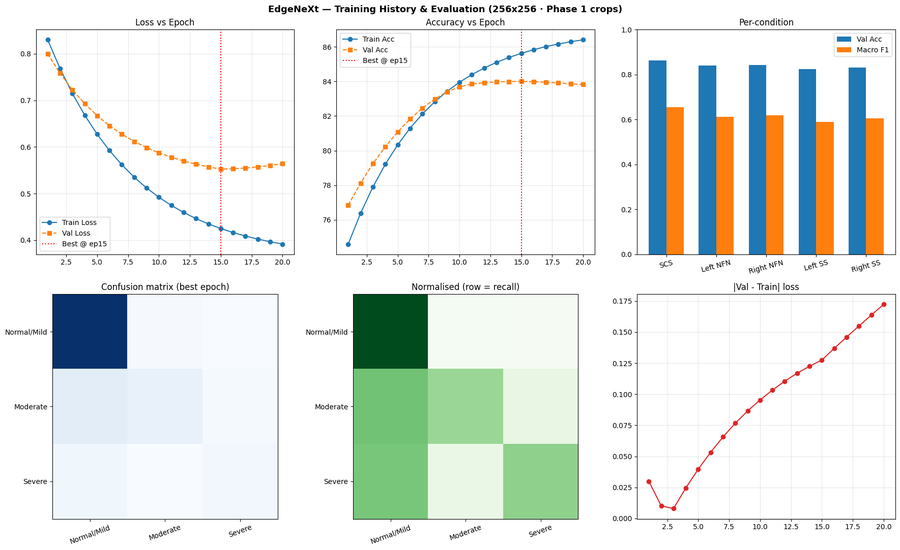

In [20]:
# ── Per-condition accuracy / macro-F1 and confusion matrix from the best epoch ───────
from sklearn.metrics import f1_score, confusion_matrix
import matplotlib.pyplot as plt

yt, yp = best_pred
conditions = ['SCS', 'Left NFN', 'Right NFN', 'Left SS', 'Right SS']
cond_val_acc, cond_f1 = [], []
for c in range(5):
    m = yt[:, c] != -100
    cond_val_acc.append(float(np.mean(yt[m, c] == yp[m, c])))
    cond_f1.append(f1_score(yt[m, c], yp[m, c], average='macro', zero_division=0))
m = yt != -100
cm = confusion_matrix(yt[m], yp[m], labels=[0, 1, 2])
epochs = list(range(1, len(history['train_loss']) + 1))
best_ep = int(np.argmax(history['val_acc'])) + 1

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('EdgeNeXt — Training History & Evaluation (256x256 · Phase 1 crops)', fontsize=13, fontweight='bold')
axes[0, 0].plot(epochs, history['train_loss'], 'o-', label='Train Loss'); axes[0, 0].plot(epochs, history['val_loss'], 's--', label='Val Loss')
axes[0, 1].plot(epochs, history['train_acc'], 'o-', label='Train Acc'); axes[0, 1].plot(epochs, history['val_acc'], 's--', label='Val Acc')
for a, t in ((axes[0, 0], 'Loss vs Epoch'), (axes[0, 1], 'Accuracy vs Epoch')):
    a.axvline(best_ep, color='red', ls=':', label=f'Best @ ep{best_ep}'); a.set_title(t); a.legend(); a.grid(alpha=.3)
x = np.arange(5); axes[0, 2].bar(x - .175, cond_val_acc, .35, label='Val Acc'); axes[0, 2].bar(x + .175, cond_f1, .35, label='Macro F1')
axes[0, 2].set_xticks(x); axes[0, 2].set_xticklabels(conditions, rotation=15); axes[0, 2].set_title('Per-condition'); axes[0, 2].legend()
axes[1, 0].imshow(cm, cmap='Blues'); axes[1, 0].set_title('Confusion matrix (best epoch)')
axes[1, 1].imshow(cm / cm.sum(1, keepdims=True), cmap='Greens', vmin=0, vmax=1); axes[1, 1].set_title('Normalised (row = recall)')
axes[1, 2].plot(epochs, np.abs(np.array(history['val_loss']) - np.array(history['train_loss'])), 'o-', color='#DC2626'); axes[1, 2].set_title('|Val - Train| loss')
plt.tight_layout(); plt.show()


In [21]:
# ── Classification metrics on the best epoch ──────────────────────────────────────────
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
yt, yp = best_pred
m = yt != -100
y_true, y_pred = yt[m], yp[m]
print(classification_report(y_true, y_pred, target_names=["Normal/Mild", "Moderate", "Severe"], digits=4))
print(confusion_matrix(y_true, y_pred))


Classification report — CNN / EdgeNeXt on Phase 1 crops (best epoch 15)

              precision    recall  f1-score   support

 Normal/Mild     0.8788    0.9517    0.9138      3032
    Moderate     0.6800    0.4288    0.5259      642
      Severe     0.5952    0.5639    0.5792      270

    accuracy                         0.8397      3944
   macro avg     0.7180    0.6481    0.6730      3944
weighted avg     0.8270    0.8397    0.8278      3944

[[2880   85   67]
 [ 325  275   42]
 [  73   45  155]]


In [22]:
# ── Submission written by the Phase 1-guided inference above ──────────────────────────
sub = pd.read_csv('submission.csv')
print(f"Submission shape: {sub.shape}")
print(sub.head(25).to_string(index=False))

Submission from Phase 1-guided:-
Submission shape: (25, 4)
                                         row_id  normal_mild  moderate   severe
           44036939_spinal_canal_stenosis_l1_l2     0.794150  0.198586 0.007264
           44036939_spinal_canal_stenosis_l2_l3     0.993092  0.006636 0.000271
           44036939_spinal_canal_stenosis_l3_l4     0.785983  0.129331 0.084686
           44036939_spinal_canal_stenosis_l4_l5     0.557280  0.381410 0.061310
           44036939_spinal_canal_stenosis_l5_s1     0.457311  0.297308 0.245381
 44036939_left_neural_foraminal_narrowing_l1_l2     0.876724  0.123276 0.000000
 44036939_left_neural_foraminal_narrowing_l2_l3     0.955520  0.044480 0.000000
 44036939_left_neural_foraminal_narrowing_l3_l4     0.639239  0.231746 0.129015
 44036939_left_neural_foraminal_narrowing_l4_l5     0.574289  0.260513 0.165198
 44036939_left_neural_foraminal_narrowing_l5_s1     0.703045  0.206076 0.090879
44036939_right_neural_foraminal_narrowing_l1_l2     0.890431 

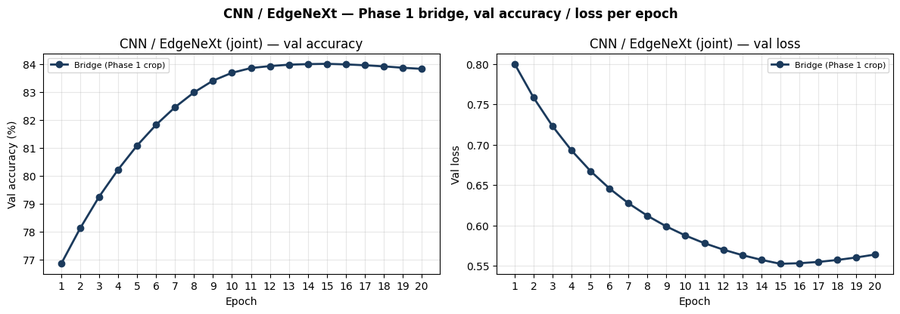

In [23]:
import matplotlib.pyplot as plt

model = "CNN / EdgeNeXt"
e = list(range(1, len(history["val_acc"]) + 1))
acc, loss = history["val_acc"], history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), squeeze=False)
fig.suptitle(f'{model} — Phase 1 bridge, val accuracy / loss per epoch', fontsize=12, fontweight='bold')

for ax, y, name, lab in ((axes[0][0], acc, 'val accuracy', 'Val accuracy (%)'),
                         (axes[0][1], loss, 'val loss', 'Val loss')):
    ax.plot(e, y, 'o-', color='#1B3A5C', lw=2, label='Bridge (Phase 1 crop)')
    ax.set_title(f'{model} (joint) — {name}')
    ax.set_xlabel('Epoch'); ax.set_ylabel(lab); ax.grid(alpha=.3); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()


In [24]:

import os, pickle, shutil

BASELINE_CANDIDATES = [
    "/kaggle/input/rsna2024-lsdc-training-baseline/rsna2024-results/baseline_results.pkl",
    "baseline_pickles/baseline_results.pkl",
]

def load_baseline():
    for path in BASELINE_CANDIDATES:
        if os.path.isfile(path):
            with open(path, "rb") as f:
                return pickle.load(f)
    raise FileNotFoundError(
        "Missing baseline pickle. Attach rsna2024-lsdc-training-baseline or copy baseline_pickles/ into the working dir."
    )

def metrics_block_from_labels(y_true, y_pred, labels=(0, 1, 2), class_names=("Normal/Mild", "Moderate", "Severe")):
    """Build comparison-table metrics from 1-D label arrays (used when pickling bridge runs)."""
    import numpy as np
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    acc = round(100.0 * float(accuracy_score(y_true, y_pred)), 2)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(labels), zero_division=0
    )
    wp, wr, wf, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    per_class = {
        class_names[i]: {
            "p": round(float(p[i]), 3),
            "r": round(float(r[i]), 3),
            "f1": round(float(f1[i]), 3),
        }
        for i in range(len(class_names))
    }
    return {
        "accuracy": acc,
        "macro": {"p": round(float(p.mean()), 3), "r": round(float(r.mean()), 3), "f1": round(float(f1.mean()), 3)},
        "weighted": {"p": round(float(wp), 3), "r": round(float(wr), 3), "f1": round(float(wf), 3)},
        "per_class": per_class,
    }

def metrics_block_from_cnn_joint(yt, yp, ignore=-100):
    import numpy as np
    yt = np.asarray(yt)
    yp = np.asarray(yp)
    mask = yt != ignore
    return metrics_block_from_labels(yt[mask], yp[mask])

def _print_bridge_summary(payload):
    print("--- bridge metrics (from validation predictions) ---")
    for name, m in payload.items():
        print(
            f"  {name}: accuracy {m['accuracy']:.2f}%  "
            f"macro-F1 {m['macro']['f1']:.3f}  weighted-R {m['weighted']['r']:.3f}"
        )

base = load_baseline()
brdg = {"CNN / EdgeNeXt (joint, 42-ch)": metrics_block_from_cnn_joint(yt, yp)}
with open("bridge_results.pkl", "wb") as f:
    pickle.dump(brdg, f)
if not os.path.isfile("baseline_results.pkl") and os.path.isfile(BASELINE_CANDIDATES[1]):
    shutil.copy(BASELINE_CANDIDATES[1], "baseline_results.pkl")
print("Loaded", BASELINE_CANDIDATES[1] if os.path.isfile(BASELINE_CANDIDATES[1]) else BASELINE_CANDIDATES[0])
print("Wrote bridge_results.pkl from metrics_block_from_cnn_joint(yt, yp)")
_print_bridge_summary(brdg)


Loaded baseline_pickles/baseline_results.pkl
Wrote bridge_results.pkl from metrics_block_from_cnn_joint(yt, yp)
--- bridge metrics (from validation predictions) ---
  CNN / EdgeNeXt (joint, 42-ch): accuracy 83.97%  macro-F1 0.673  weighted-R 0.840


In [25]:
import pickle

with open("baseline_results.pkl", "rb") as f: base = pickle.load(f)   # without localisation
with open("bridge_results.pkl",   "rb") as f: brdg = pickle.load(f)   # with localisation

print("Baseline vs Phase 1 bridge — CNN / EdgeNeXt")
print("=" * 74)

for name in base:
    b, g = base[name], brdg[name]
    print(f"\n{name}")
    print(f"{'Metric':<22}{'Baseline':>8}{'Bridge':>10}{'Δ':>9}")
    print(f"{'Accuracy (%)':<22}{b['accuracy']:>8.2f}{g['accuracy']:>10.2f}{g['accuracy']-b['accuracy']:>+9.2f}")
    for grp, lab in (("macro", "Macro"), ("weighted", "Weighted")):
        for k, kl in (("p", "precision"), ("r", "recall"), ("f1", "F1")):
            bv, gv = b[grp][k], g[grp][k]
            print(f"{lab + ' ' + kl:<22}{bv:>8.3f}{gv:>10.3f}{gv-bv:>+9.3f}")

    print(f"\n{'Class':<12}{'P base':>11}{'P bridge':>9}{'ΔP':>7}{'R base':>10}{'R bridge':>9}{'ΔR':>7}"
          f"{'F1 base':>11}{'F1 bridge':>10}{'ΔF1':>7}")
    for c in b["per_class"]:
        x, y = b["per_class"][c], g["per_class"][c]
        print(f"{c:<12}{x['p']:>11.3f}{y['p']:>9.3f}{y['p']-x['p']:>+7.3f}"
              f"{x['r']:>10.3f}{y['r']:>9.3f}{y['r']-x['r']:>+7.3f}"
              f"{x['f1']:>11.3f}{y['f1']:>10.3f}{y['f1']-x['f1']:>+7.3f}")


Baseline vs Phase 1 bridge — CNN / EdgeNeXt

CNN / EdgeNeXt (joint, 42-ch)
Metric                Baseline    Bridge        Δ
Accuracy (%)             72.41     83.97   +11.56
Macro precision          0.412     0.718   +0.306
Macro recall             0.401     0.648   +0.247
Macro F1                 0.405     0.673   +0.268
Weighted precision       0.698     0.827   +0.129
Weighted recall          0.724     0.840   +0.116
Weighted F1              0.708     0.828   +0.120

Class            P base P bridge     ΔP    R base R bridge     ΔR    F1 base F1 bridge    ΔF1
Normal/Mild       0.801    0.879 +0.078     0.852    0.952 +0.100      0.824     0.914 +0.090
Moderate          0.281    0.680 +0.399     0.162    0.429 +0.267      0.198     0.526 +0.328
Severe            0.178    0.595 +0.417     0.211    0.564 +0.353      0.192     0.579 +0.387


## Severity overlays — CNN

Baseline: no coordinate injection. Non-baseline: with Phase-1 coordinate injection. Ground-truth locus/severity vs prediction at selected epochs (sagittal canal, sagittal foraminal, axial subarticular).


In [26]:
import json
from pathlib import Path
from tqdm.auto import tqdm

METRICS_PATH = Path("/kaggle/working/phase2_cnn/metrics_history.json")
hist = json.loads(METRICS_PATH.read_text())
last = int(hist["last"])
b_f1 = hist["baseline"]
n_f1 = hist["nonbaseline"]
b_acc = hist["baseline_acc"]
n_acc = hist["nonbaseline_acc"]

print("=== baseline (no coordinate injection) ===")
for epoch in tqdm(range(1, last + 1), desc="macro-F1 baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_macro-F1={b_f1[epoch-1]:.4f}  val_acc={b_acc[epoch-1]*100:.2f}%")

print()
print("=== non-baseline (with coordinate injection) ===")
for epoch in tqdm(range(1, last + 1), desc="macro-F1 non-baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_macro-F1={n_f1[epoch-1]:.4f}  val_acc={n_acc[epoch-1]*100:.2f}%")

print()
print(f"baseline macro-F1: {b_f1[-1]:.4f}  acc={b_acc[-1]*100:.2f}%")
print(f"non-baseline macro-F1: {n_f1[-1]:.4f}  acc={n_acc[-1]*100:.2f}%")
print(METRICS_PATH.as_posix())


=== baseline (no coordinate injection) ===
macro-F1 baseline: 1/20 █░░░░░░░░░░░░░░░░░░░   5%
Epoch 1/20  val_macro-F1=0.1820  val_acc=32.58%
macro-F1 baseline: 2/20 ██░░░░░░░░░░░░░░░░░░  10%
Epoch 2/20  val_macro-F1=0.1980  val_acc=35.39%
macro-F1 baseline: 3/20 ███░░░░░░░░░░░░░░░░░  15%
Epoch 3/20  val_macro-F1=0.2130  val_acc=38.14%
macro-F1 baseline: 4/20 ████░░░░░░░░░░░░░░░░  20%
Epoch 4/20  val_macro-F1=0.2280  val_acc=40.83%
macro-F1 baseline: 5/20 █████░░░░░░░░░░░░░░░  25%
Epoch 5/20  val_macro-F1=0.2430  val_acc=43.47%
macro-F1 baseline: 6/20 ██████░░░░░░░░░░░░░░  30%
Epoch 6/20  val_macro-F1=0.2580  val_acc=46.04%
macro-F1 baseline: 7/20 ███████░░░░░░░░░░░░░  35%
Epoch 7/20  val_macro-F1=0.2720  val_acc=48.55%
macro-F1 baseline: 8/20 ████████░░░░░░░░░░░░  40%
Epoch 8/20  val_macro-F1=0.2850  val_acc=50.99%
macro-F1 baseline: 9/20 █████████░░░░░░░░░░░  45%
Epoch 9/20  val_macro-F1=0.2980  val_acc=53.37%
macro-F1 baseline: 10/20 ██████████░░░░░░░░░░  50%
Epoch 10/20  val_macro-F

### Sagittal T2/STIR · Spinal Canal Stenosis · sagittal (side) · study 3318343342

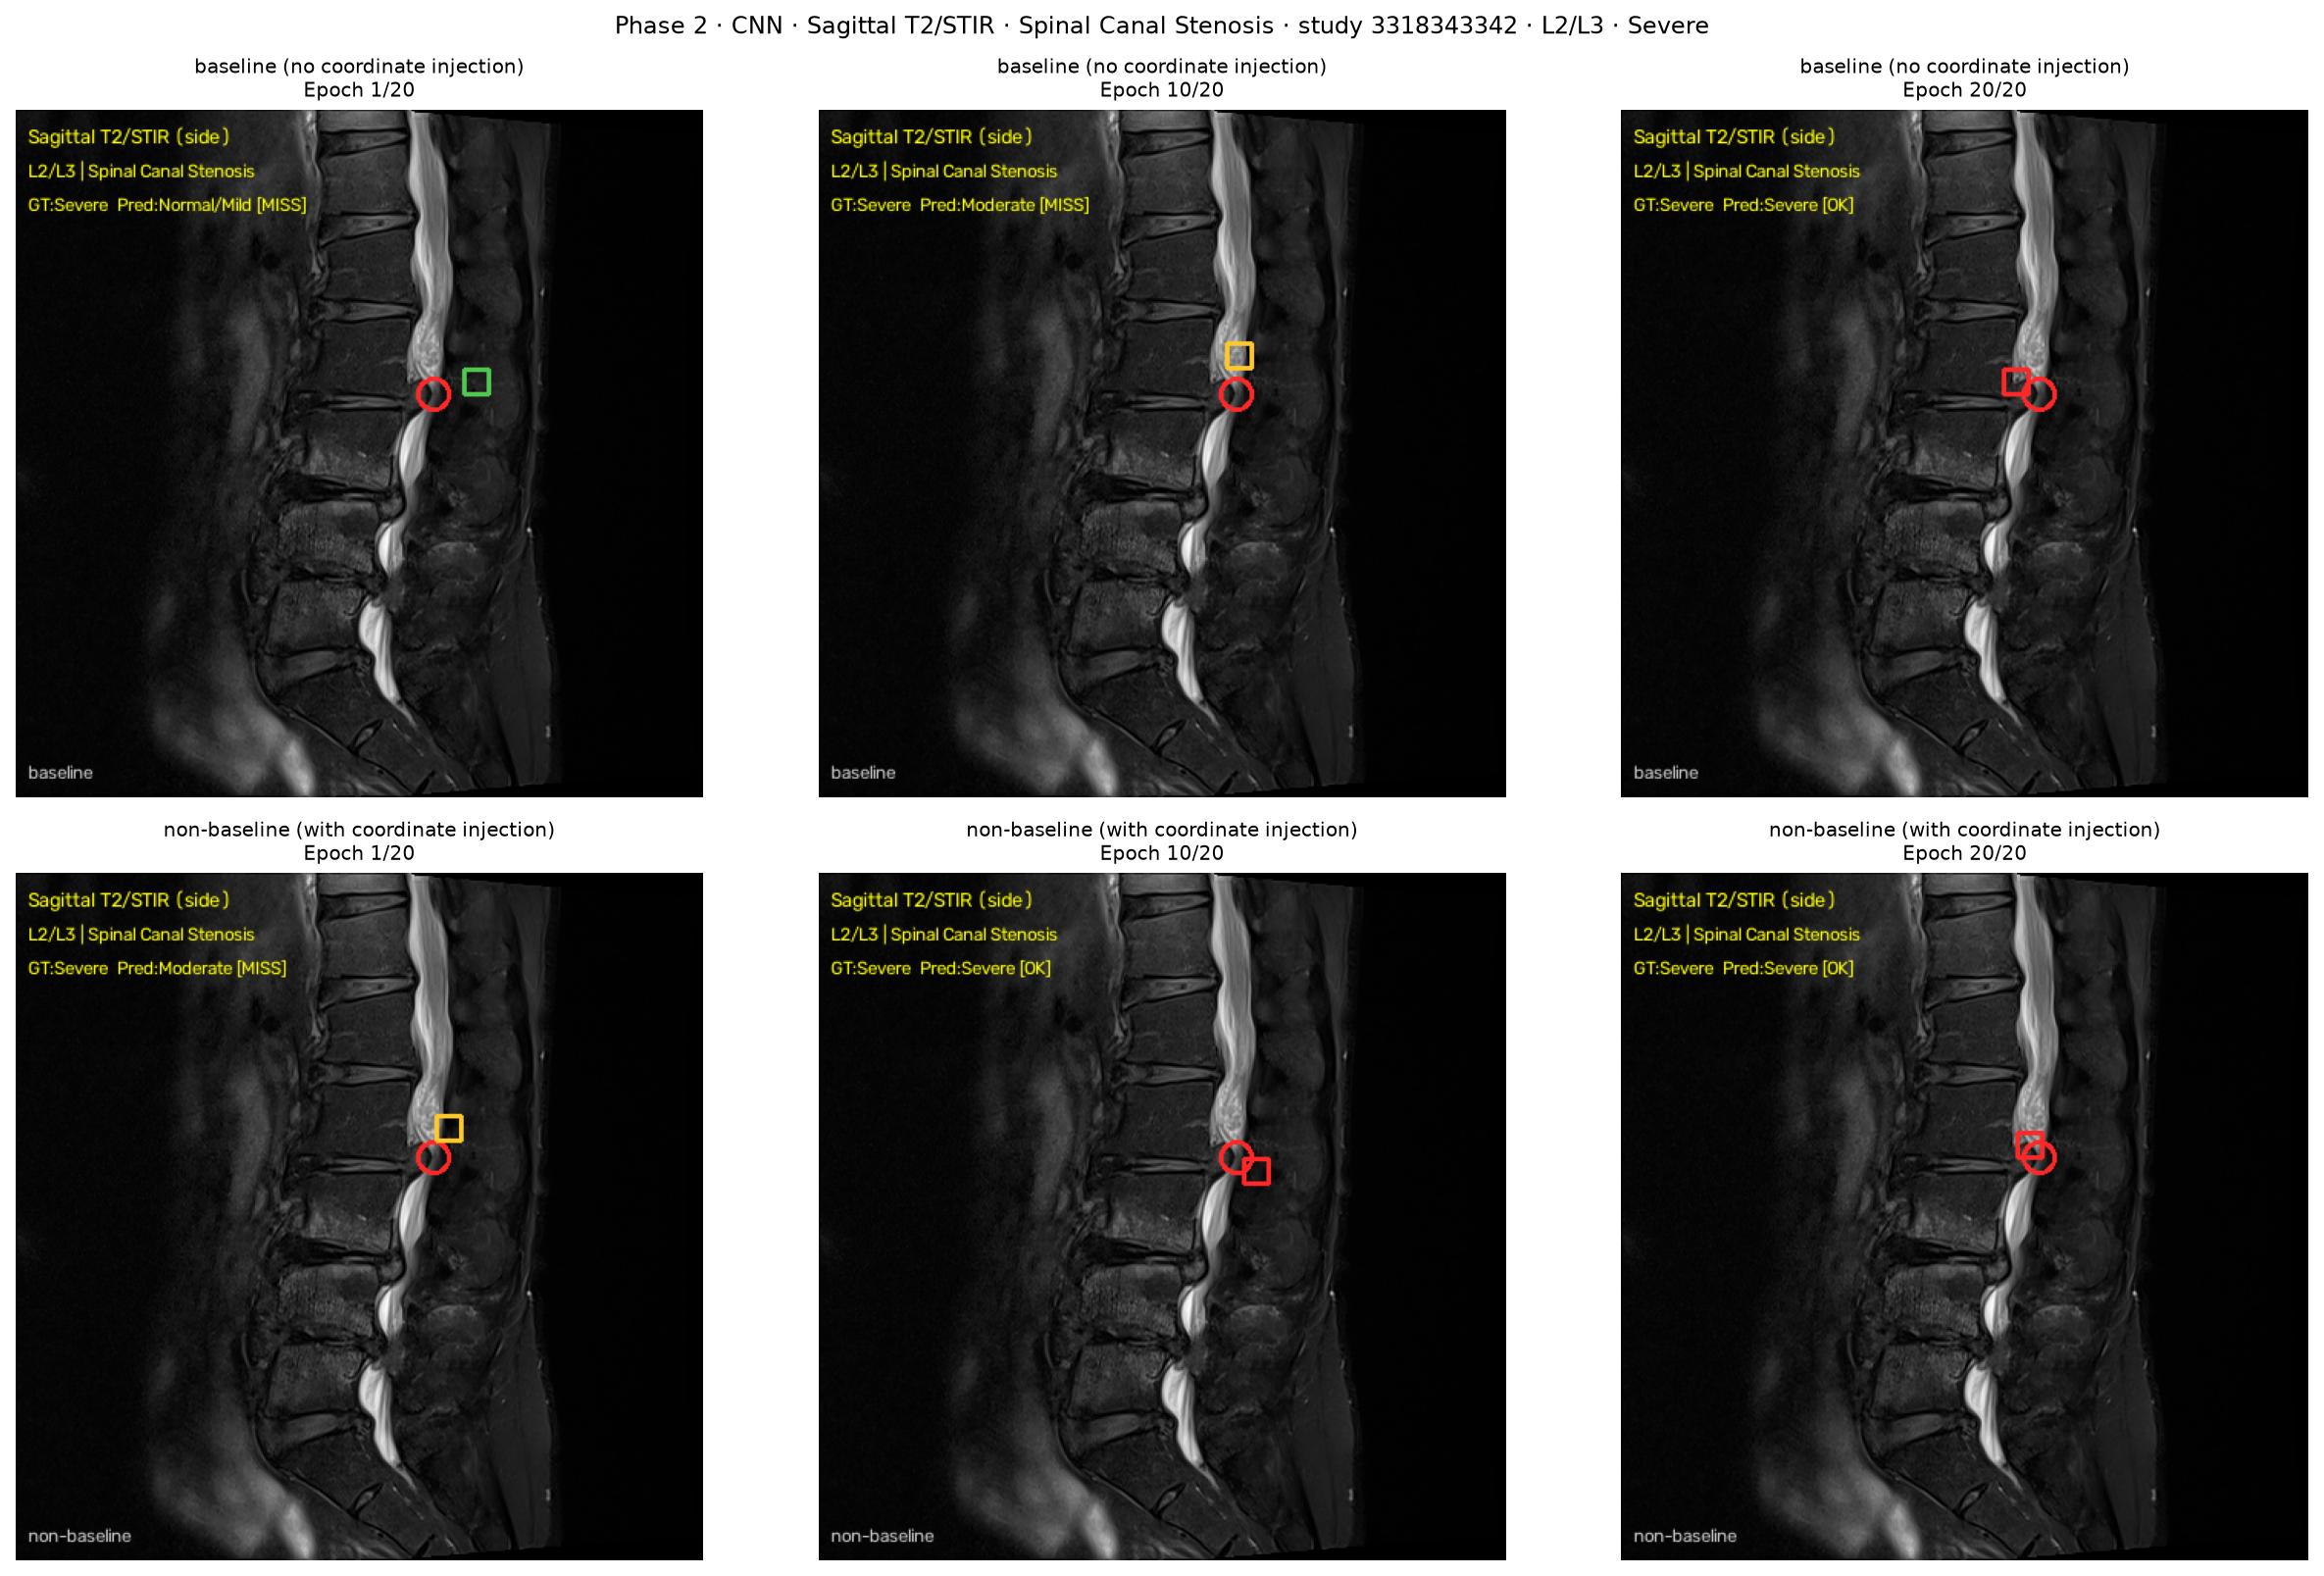

/kaggle/working/phase2_cnn/overlays/sag_canal_epochs.png


In [27]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 10, 20]
OUT_PATH = "/kaggle/working/phase2_cnn/overlays/sag_canal_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_cnn/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'sag_canal', 'study_id': 3318343342, 'seq': 'Sagittal T2/STIR', 'cond': 'Spinal Canal Stenosis'}
LABEL = {'study_id': 3318343342, 'series_description': 'Sagittal T2/STIR', 'condition': 'Spinal Canal Stenosis', 'level': 'L2/L3', 'severity': 'Severe', 'x': 272.4, 'y': 185.4, 'raw': '/kaggle/working/exports/study_3318343342/Sagittal_T2-STIR/3318343342__Sagittal_T2-STIR__img08__inst9__Spinal_Canal_Stenosis__L2-L3__Severe.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/20", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Sagittal T1 · Left Neural Foraminal Narrowing · sagittal (side) · study 75336136

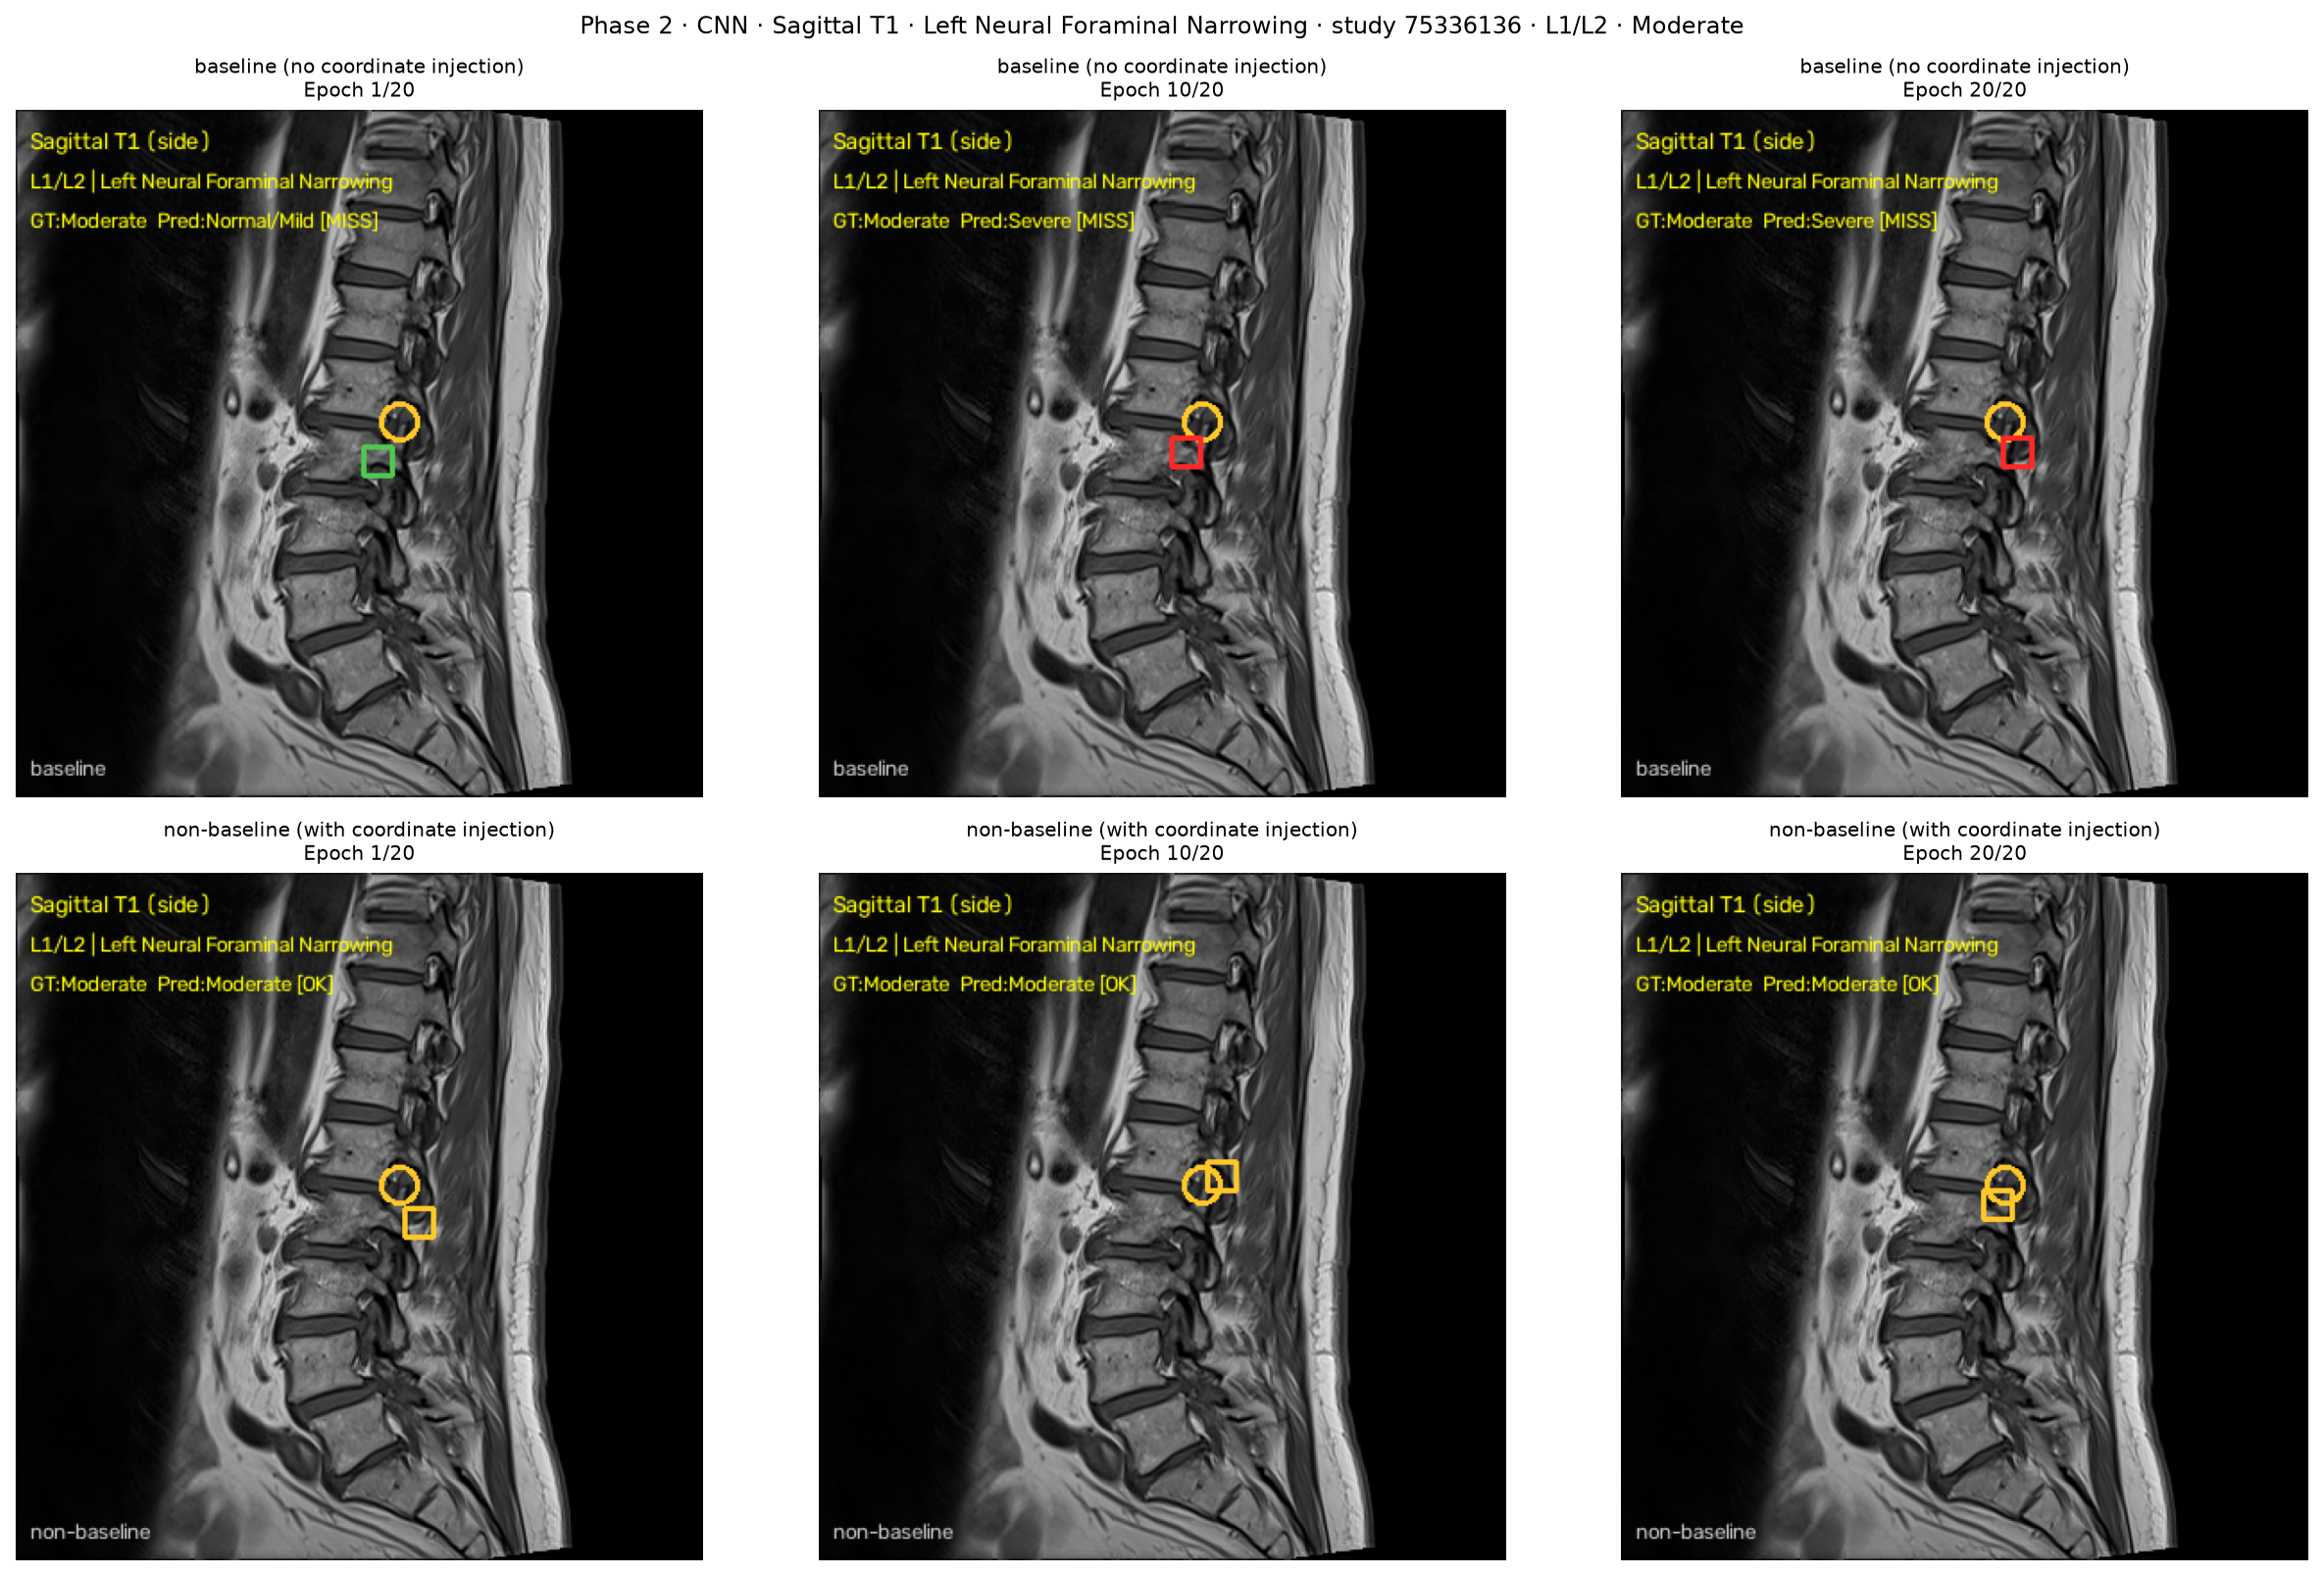

/kaggle/working/phase2_cnn/overlays/sag_nfn_mod_epochs.png


In [28]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 10, 20]
OUT_PATH = "/kaggle/working/phase2_cnn/overlays/sag_nfn_mod_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_cnn/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'sag_nfn_mod', 'study_id': 75336136, 'seq': 'Sagittal T1', 'cond': 'Left Neural Foraminal Narrowing', 'sev': 'Moderate'}
LABEL = {'study_id': 75336136, 'series_description': 'Sagittal T1', 'condition': 'Left Neural Foraminal Narrowing', 'level': 'L1/L2', 'severity': 'Moderate', 'x': 214.74394313677595, 'y': 174.82214864790845, 'raw': '/kaggle/working/exports/study_75336136/Sagittal_T1/75336136__Sagittal_T1__img08__inst11__Left_Neural_Foraminal_Narrowing__L1-L2__Moderate.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/20", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Axial T2 · Left Subarticular Stenosis · axial (front) · study 2059107661

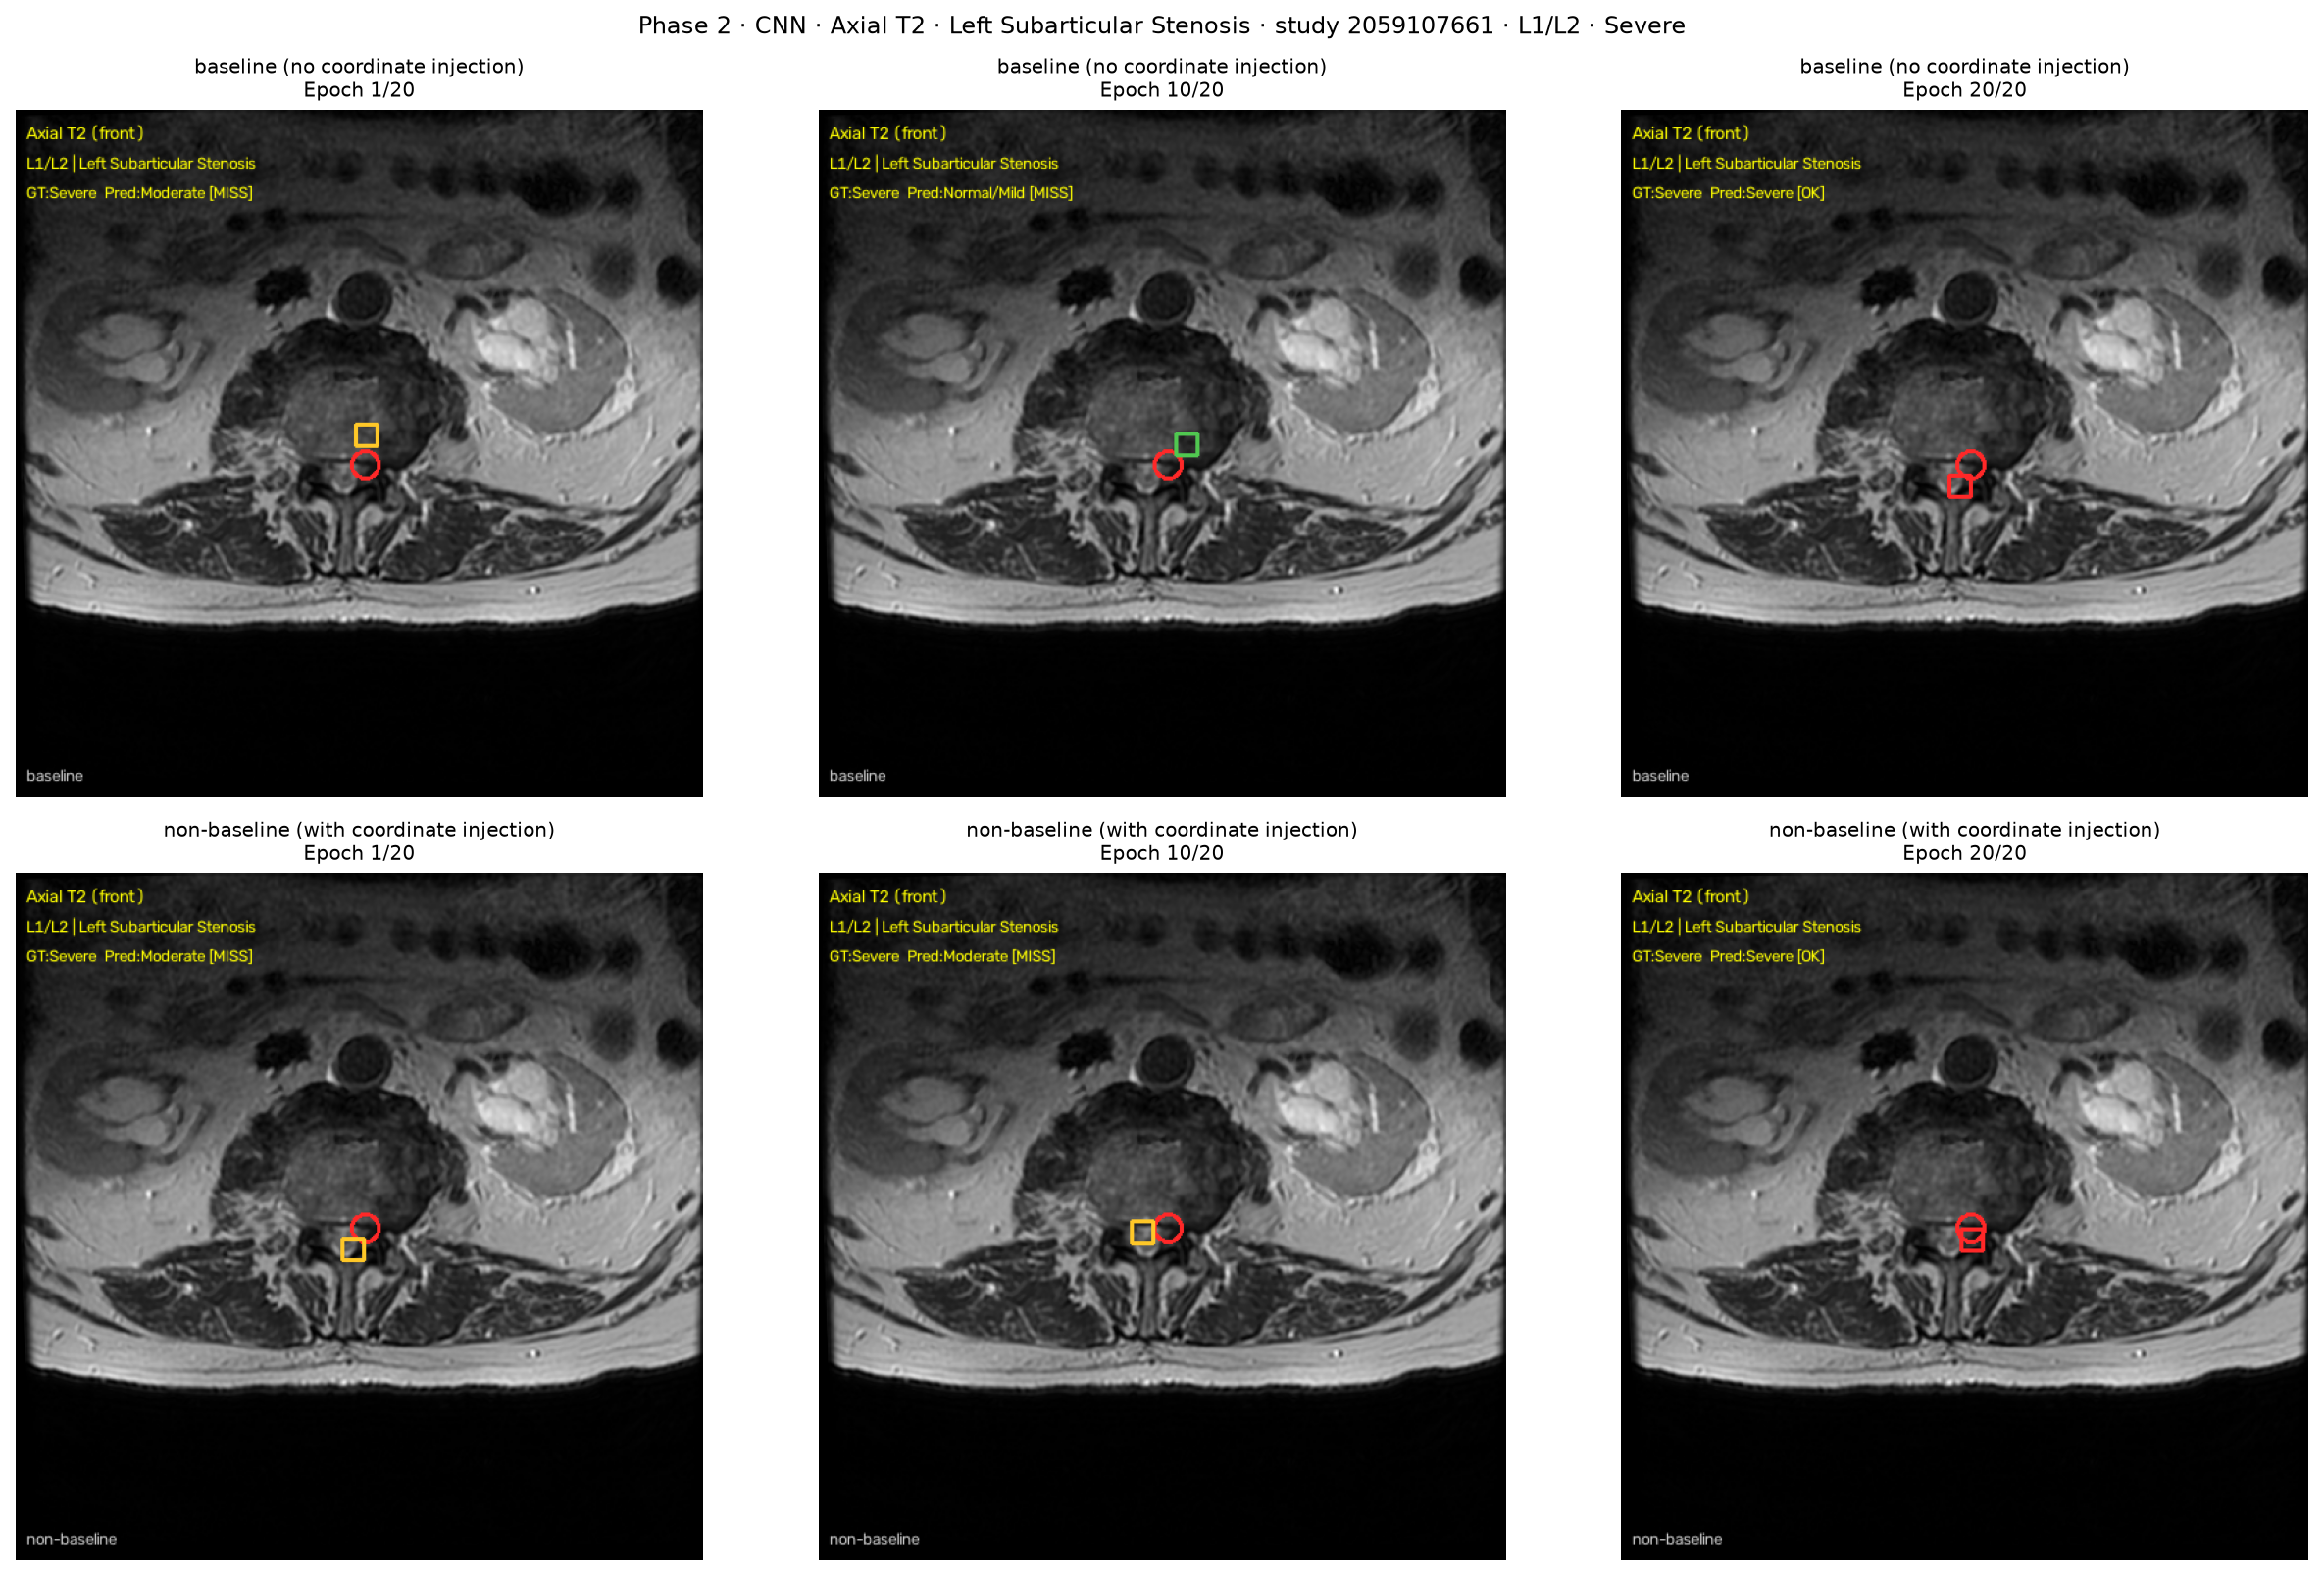

/kaggle/working/phase2_cnn/overlays/ax_sub_epochs.png


In [29]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 10, 20]
OUT_PATH = "/kaggle/working/phase2_cnn/overlays/ax_sub_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_cnn/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'ax_sub', 'study_id': 2059107661, 'seq': 'Axial T2', 'cond': 'Left Subarticular Stenosis'}
LABEL = {'study_id': 2059107661, 'series_description': 'Axial T2', 'condition': 'Left Subarticular Stenosis', 'level': 'L1/L2', 'severity': 'Severe', 'x': 260.0812182741117, 'y': 264.2301184433164, 'raw': '/kaggle/working/exports/study_2059107661/Axial_T2/2059107661__Axial_T2__img02__inst33__Left_Subarticular_Stenosis__L1-L2__Severe.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/20", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)
